In [ ]:
!pip uninstall -y numpy
!pip install numpy==1.26.4
!pip install scikit-surprise --prefer-binary

Found existing installation: numpy 2.5.5
Uninstalling numpy-2.5.5:
  Successfully uninstalled numpy-2.5.5


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
netflix_dataset = pd.read_csv('/content/combined_data_1.txt',header =None, names = ['Cust_Id', 'Rating'], usecols = [0,1])
netflix_dataset

,Cust_Id,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


In [ ]:
netflix_dataset.tail()

,Cust_Id,Rating
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0
24058262,1704416,3.0


In [ ]:
netflix_dataset.dtypes

Cust_Id        str
Rating     float64
dtype: object

In [ ]:
netflix_dataset.isnull().sum()

Cust_Id       0
Rating     4499
dtype: int64

Finding the movie count by assumiung that if there is NaN in Rating columns so front of it, there is a movie id

In [ ]:
movie_count = netflix_dataset.isnull().sum()
movie_count = movie_count["Rating"]
movie_count

np.int64(4499)

Finding the total unique customer id by substracting the movie count from unique values in cust id column

In [ ]:
customer_count = netflix_dataset['Cust_Id'].nunique()
customer_count

475257

In [ ]:
customer_count-movie_count

np.int64(470758)

We have total 4 lakh, 70 thoushand and 7 hundered 58 unique customers

In [ ]:
#get the total number of rating given by the customer to all movie combined

rating_count = netflix_dataset['Cust_Id'].count()-movie_count # In Customer id column we will remove movie id to get how many total rating
rating_count

np.int64(24053764)

In [ ]:
stars = netflix_dataset.groupby('Rating')['Rating'].agg(['count'])
stars

,count
Rating,
1.0,1118186
2.0,2439073
3.0,6904181
4.0,8085741
5.0,5506583


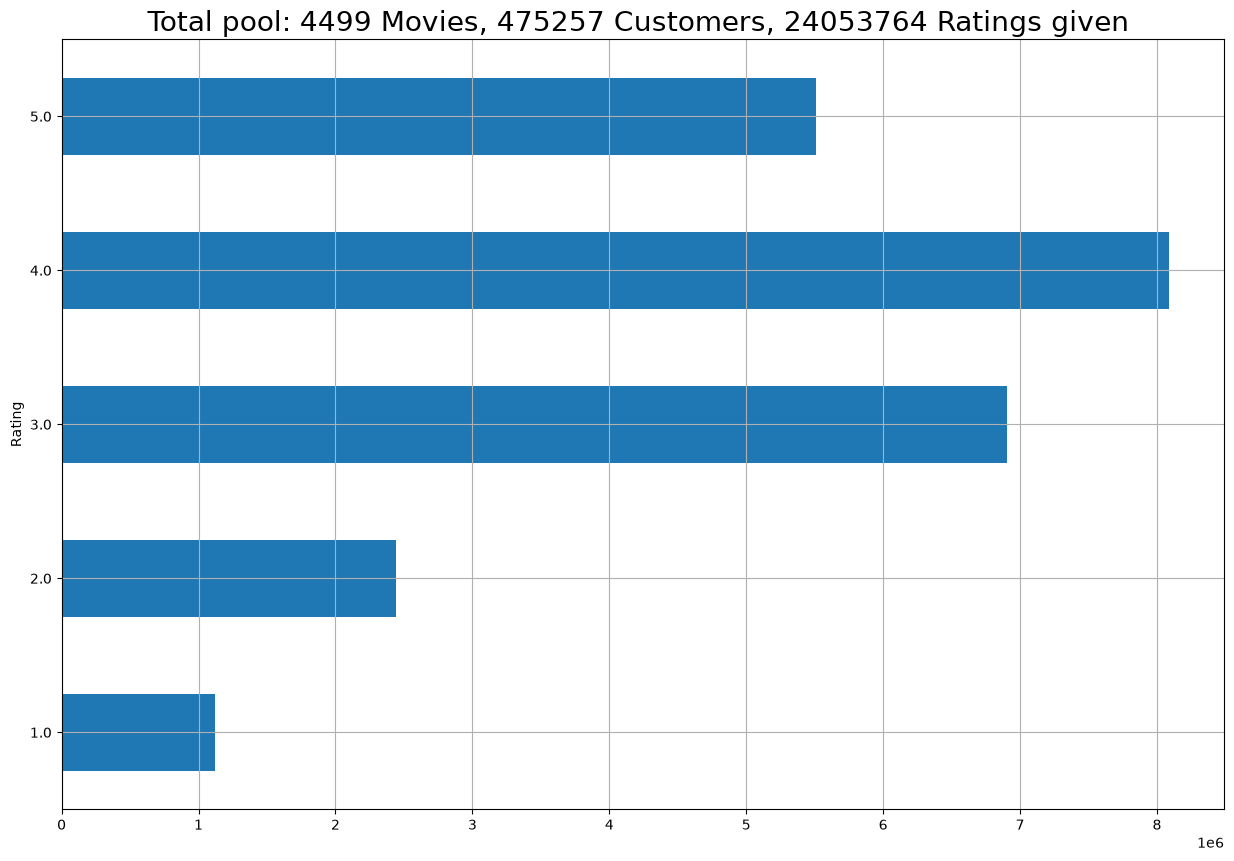

In [ ]:
ax =stars.plot(kind='barh', legend=False ,figsize=(15,10))

plt.title(f'Total pool: {movie_count} Movies, {customer_count} Customers, {rating_count} Ratings given ', fontsize=20)
plt.grid(True)

In [ ]:
netflix_dataset

,Cust_Id,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


In [ ]:
# Lets just make a clear dataframe to find how many MovieId are there
movie_id = None
movie_np = []

# Iterate over the DataFrame rows
for cust_id in netflix_dataset['Cust_Id']:
  if ':' in cust_id:
    #update the current movie ID
    movie_id = int(cust_id.replace(':', ''))
  movie_np.append(movie_id)

In [ ]:
movie_np # Movie id columns that we can add in our dataset

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [ ]:
# add the new columns to the DataFrame
netflix_dataset['Movie_Id'] = movie_np

In [ ]:
netflix_dataset

,Cust_Id,Rating,Movie_Id
0,1:,NaN,1
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [ ]:
netflix_dataset =netflix_dataset[netflix_dataset['Rating'].notna()]
# to keep only the rows where the 'Rating' columns is not null ( i.e., it excludes rows where the 'Rating' is NaN)

In [ ]:
netflix_dataset

,Cust_Id,Rating,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [ ]:
netflix_dataset.info()

<class 'pandas.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column    Dtype  
---  ------    -----  
 0   Cust_Id   str    
 1   Rating    float64
 2   Movie_Id  int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 887.9 MB


In [ ]:
netflix_dataset['Cust_Id'] = netflix_dataset['Cust_Id'].astype(int)
netflix_dataset

,Cust_Id,Rating,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [ ]:
netflix_dataset.info()

<class 'pandas.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column    Dtype  
---  ------    -----  
 0   Cust_Id   int64  
 1   Rating    float64
 2   Movie_Id  int64  
dtypes: float64(1), int64(2)
memory usage: 734.1 MB


#pre-filtering
#now we will remove all the users that have rated less movies and also all those movie that has been rated less in number


In [ ]:
dataset_movie_summary = netflix_dataset.groupby('Movie_Id')['Rating'].agg(['count'])

In [ ]:
dataset_movie_summary

,count
Movie_Id,
1,547
2,145
3,2012
4,142
5,1140
...,...
4495,614
4496,9519
4497,714


In [ ]:
# now we will create a benchmark

movie_benchmark = round(dataset_movie_summary['count'].quantile(0.6),0)
movie_benchmark

np.float64(908.0)

In [ ]:
drop_movie_list = dataset_movie_summary[dataset_movie_summary['count']<movie_benchmark].index

In [ ]:
drop_movie_list  # in thes list all movie are there those are having less rating then benchmark so remove them

Index([   1,    2,    4,    7,    9,   10,   11,   12,   13,   14,
       ...
       4480, 4481, 4486, 4487, 4491, 4494, 4495, 4497, 4498, 4499],
      dtype='int64', name='Movie_Id', length=2699)

In [ ]:
len(drop_movie_list)

2699

In [ ]:
4499-2699 #movie left

1800

In [ ]:
#now we will removie all the user that are in-active

dataset_cust_summary = netflix_dataset.groupby('Cust_Id')['Rating'].agg(['count'])

In [ ]:
dataset_cust_summary

,count
Cust_Id,
6,153
7,195
8,21
10,49
25,4
...,...
2649404,12
2649409,10
2649421,3


In [ ]:
cust_benchmark = round(dataset_cust_summary['count'].quantile(0.6),0)
cust_benchmark

np.float64(36.0)

In [ ]:
drop_cust_list = dataset_cust_summary[dataset_cust_summary['count']<cust_benchmark].index

In [ ]:
drop_cust_list

Index([      8,      25,      33,      83,      94,     126,     130,     133,
           142,     149,
       ...
       2649337, 2649343, 2649351, 2649376, 2649379, 2649384, 2649401, 2649404,
       2649409, 2649421],
      dtype='int64', name='Cust_Id', length=282042)

In [ ]:
len(drop_cust_list)

282042

let remove all movie that has been rated less than 908 times

lets removie all customer that have rated less then 36 movies

In [ ]:
netflix_dataset = netflix_dataset[~netflix_dataset['Movie_Id'].isin(drop_movie_list)]
netflix_dataset = netflix_dataset[~netflix_dataset['Cust_Id'].isin(drop_cust_list)]
print('After the triming, the shape isL {}'.format(netflix_dataset.shape))

After the triming, the shape isL (19695836, 3)


In [ ]:
netflix_dataset  #clean netflix data !

,Cust_Id,Rating,Movie_Id
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
700,656399,4.0,3
...,...,...,...
24056842,1055714,5.0,4496
24056843,2643029,4.0,4496
24056844,267802,4.0,4496
24056845,1559566,3.0,4496


**MODEL BUILDING**


In [ ]:
df_title = pd.read_csv('/content/movie_titles.csv', encoding = "latin", header = None, usecols=[0,1,2], names = ['Movie_Id', 'Year', 'Name'])

In [ ]:
df_title

,Movie_Id,Year,Name
0,1,2003.0,Dinosaur Planet
1,2,2004.0,Isle of Man TT 2004 Review
2,3,1997.0,Character
3,4,1994.0,Paula Abdul's Get Up & Dance
4,5,2004.0,The Rise and Fall of ECW
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
from surprise import Reader, Dataset, SVD
from surprise.model_selection import cross_validate

In [ ]:
reader = Reader()
data = Dataset.load_from_df(netflix_dataset[['Cust_Id', 'Movie_Id', 'Rating']] [:100000], reader)

In [ ]:
model = SVD()  # creating a SVD model

In [ ]:
cross_validate(model, data, measures=['RMSE'], cv=3) # Trained the model

{'test_rmse': array([1.02373881, 1.01599247, 1.02121072]),
 'fit_time': (1.3556160926818848, 0.9119408130645752, 0.9603269100189209),
 'test_time': (0.13563227653503418, 0.13138461112976074, 0.12816309928894043)}

Use model for making Recommendation for a specific user

In [ ]:
netflix_dataset

,Cust_Id,Rating,Movie_Id
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
700,656399,4.0,3
...,...,...,...
24056842,1055714,5.0,4496
24056843,2643029,4.0,4496
24056844,267802,4.0,4496
24056845,1559566,3.0,4496


In [ ]:
df_title

,Movie_Id,Year,Name
0,1,2003.0,Dinosaur Planet
1,2,2004.0,Isle of Man TT 2004 Review
2,3,1997.0,Character
3,4,1994.0,Paula Abdul's Get Up & Dance
4,5,2004.0,The Rise and Fall of ECW
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
# Filter the dataset for the specific user you have selected to make recommendation to that user

user_ratings = netflix_dataset[netflix_dataset['Cust_Id']==1331154]

In [ ]:
user_ratings

,Cust_Id,Rating,Movie_Id
697,1331154,4.0,3
5178,1331154,4.0,8
31460,1331154,3.0,18
92840,1331154,4.0,30
224761,1331154,3.0,44
...,...,...,...
23439584,1331154,4.0,4389
23546489,1331154,2.0,4402
23649431,1331154,4.0,4432
23844441,1331154,3.0,4472


In [ ]:
# Find the number of unique movie rated by the user

movie_rated_by_user = user_ratings['Movie_Id'].nunique()
print(f"user 1331154 has rated {movie_rated_by_user} unique movies")

user 1331154 has rated 253 unique movies


In [ ]:
copy_data_for_user = df_title.copy()   # Making a copy for each individual customer for the recommendation
copy_data_for_user

,Movie_Id,Year,Name
0,1,2003.0,Dinosaur Planet
1,2,2004.0,Isle of Man TT 2004 Review
2,3,1997.0,Character
3,4,1994.0,Paula Abdul's Get Up & Dance
4,5,2004.0,The Rise and Fall of ECW
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
CLEAN_copy_data_for_user = copy_data_for_user[~copy_data_for_user['Movie_Id'].isin(drop_movie_list)]
CLEAN_copy_data_for_user

,Movie_Id,Year,Name
2,3,1997.0,Character
4,5,2004.0,The Rise and Fall of ECW
5,6,1997.0,Sick
7,8,2004.0,What the #$*! Do We Know!?
15,16,1996.0,Screamers
...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...
17766,17767,2004.0,Fidel Castro: American Experience
17767,17768,2000.0,Epoch
17768,17769,2003.0,The Company


In [ ]:
CLEAN_copy_data_for_user['Estimate_Score'] = CLEAN_copy_data_for_user['Movie_Id'].apply(lambda x : model.predict(1331154, x).est)
#Predict the score (Rating) that a user (with user ID 1331154) might give to a list of movies.

In [ ]:
CLEAN_copy_data_for_user

,Movie_Id,Year,Name,Estimate_Score
2,3,1997.0,Character,3.634797
4,5,2004.0,The Rise and Fall of ECW,4.160778
5,6,1997.0,Sick,2.805890
7,8,2004.0,What the #$*! Do We Know!?,3.288124
15,16,1996.0,Screamers,3.079814
...,...,...,...,...
17765,17766,2002.0,Where the Wild Things Are and Other Maurice Se...,3.566710
17766,17767,2004.0,Fidel Castro: American Experience,3.566710
17767,17768,2000.0,Epoch,3.566710
17768,17769,2003.0,The Company,3.566710


In [ ]:
CLEAN_copy_data_for_user.sort_values('Estimate_Score', ascending=False)
# Descending order estimated score

,Movie_Id,Year,Name,Estimate_Score
4,5,2004.0,The Rise and Fall of ECW,4.160778
24,25,1997.0,Inspector Morse 31: Death Is Now My Neighbour,3.821295
27,28,2002.0,Lilo and Stitch,3.820789
29,30,2003.0,Something's Gotta Give,3.745158
2,3,1997.0,Character,3.634797
...,...,...,...,...
15,16,1996.0,Screamers,3.079814
16,17,2005.0,7 Seconds,3.040774
23,24,1981.0,My Bloody Valentine,3.003652
25,26,2004.0,Never Die Alone,3.002512


In [ ]:
top5_movies = CLEAN_copy_data_for_user.sort_values('Estimate_Score', ascending =False).head(5)

In [ ]:
top5_movies

,Movie_Id,Year,Name,Estimate_Score
4,5,2004.0,The Rise and Fall of ECW,4.160778
24,25,1997.0,Inspector Morse 31: Death Is Now My Neighbour,3.821295
27,28,2002.0,Lilo and Stitch,3.820789
29,30,2003.0,Something's Gotta Give,3.745158
2,3,1997.0,Character,3.634797
